In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

url = (
    "https://raw.githubusercontent.com/DataTalksClub/"
    "machine-learning-zoomcamp/main/cohorts/2026/data/"
    "car_fuel_efficiency_2026.csv"
)

In [9]:
features = [
    "engine_displacement",
    "horsepower",
    "vehicle_weight",
    "model_year",
]
target = "fuel_efficiency_mpg"

df = pd.read_csv(url)[features + [target]].copy()

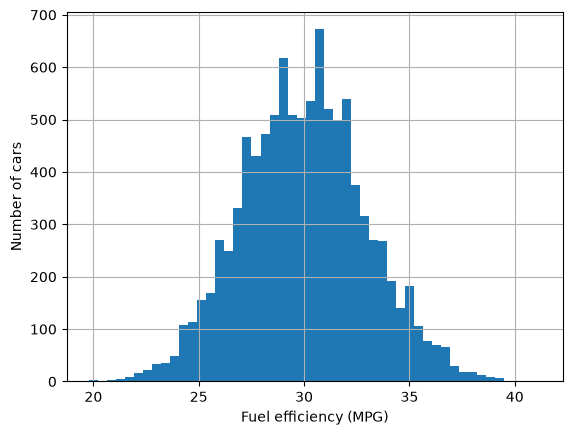

In [10]:
df[target].hist(bins=50)
plt.xlabel("Fuel efficiency (MPG)")
plt.ylabel("Number of cars")
plt.show()

In [11]:
print("Missing values:")
print(df.isna().sum())
print("Median horsepower:", df["horsepower"].median())

Missing values:
engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64
Median horsepower: 254.0


In [12]:
def split_data(df, seed):
    n = len(df)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train = df.iloc[idx[:n_train]].copy()
    df_val = df.iloc[idx[n_train:n_train + n_val]].copy()
    df_test = df.iloc[idx[n_train + n_val:]].copy()

    return df_train, df_val, df_test

In [13]:
def prepare_X(df, fill_value=0):
    return df[features].fillna(fill_value).values

def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

def train_linear_regression_reg(X, y, r=0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]


def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    return np.sqrt(se.mean())


In [15]:
df_train, df_val, df_test = split_data(df, seed=42)

y_train = df_train[target].values
y_val = df_val[target].values

mean_hp = df_train["horsepower"].mean()

for name, fill_value in [("zero", 0), ("mean", mean_hp)]:
    X_train = prepare_X(df_train, fill_value)
    X_val = prepare_X(df_val, fill_value)

    w0, w = train_linear_regression(X_train, y_train)
    y_pred = w0 + X_val.dot(w)

    print("Q3:", name, round(rmse(y_val, y_pred), 3))



Q3: zero 2.205
Q3: mean 2.202


In [16]:
X_train = prepare_X(df_train)
X_val = prepare_X(df_val)

for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    w0, w = train_linear_regression_reg(X_train, y_train, r=r)
    y_pred = w0 + X_val.dot(w)

    print("Q4:", r, round(rmse(y_val, y_pred), 4))

Q4: 0 2.2053
Q4: 0.01 2.2058
Q4: 0.1 2.2241
Q4: 1 2.3492
Q4: 5 2.4094
Q4: 10 2.4195
Q4: 100 2.4292


In [17]:
scores = []

for seed in range(10):
    df_train, df_val, df_test = split_data(df, seed)

    X_train = prepare_X(df_train)
    X_val = prepare_X(df_val)
    y_train = df_train[target].values
    y_val = df_val[target].values

    w0, w = train_linear_regression(X_train, y_train)
    y_pred = w0 + X_val.dot(w)

    score = rmse(y_val, y_pred)
    scores.append(score)
    print("Q5:", seed, score)

print("Q5 std:", round(np.std(scores), 3))

Q5: 0 2.2392041430461465
Q5: 1 2.2021128210838907
Q5: 2 2.163419778753095
Q5: 3 2.2043588768539144
Q5: 4 2.2018800943312926
Q5: 5 2.2457851509084974
Q5: 6 2.269721207952404
Q5: 7 2.190794599933433
Q5: 8 2.2166112016864443
Q5: 9 2.207036592817851
Q5 std: 0.029


In [18]:
df_train, df_val, df_test = split_data(df, seed=9)
df_full_train = pd.concat([df_train, df_val], ignore_index=True)

X_full_train = prepare_X(df_full_train)
y_full_train = df_full_train[target].values

X_test = prepare_X(df_test)
y_test = df_test[target].values

w0, w = train_linear_regression_reg(
    X_full_train, y_full_train, r=0.001
)
y_pred = w0 + X_test.dot(w)

print("Q6:", round(rmse(y_test, y_pred), 3))

Q6: 2.236
